In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
df = pd.read_csv("enron_spam_data.csv")

df.head()

In [4]:
print("Shape:", df.shape)

Shape: (33716, 5)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33716 entries, 0 to 33715
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  33716 non-null  int64 
 1   Subject     33716 non-null  object
 2   Message     33664 non-null  object
 3   Spam/Ham    33716 non-null  object
 4   Date        33716 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.3+ MB


In [6]:
df.describe()

,Unnamed: 0
count,33716.000000
mean,16857.500000
std,9733.115174
min,0.000000
25%,8428.750000
50%,16857.500000
75%,25286.250000
max,33715.000000


In [7]:
df.columns

Index(['Unnamed: 0', 'Subject', 'Message', 'Spam/Ham', 'Date'], dtype='object')

In [8]:
df.isna().sum()

Unnamed: 0     0
Subject        0
Message       52
Spam/Ham       0
Date           0
dtype: int64

In [10]:
print("Duplicated rows:",df.duplicated().sum())

Duplicated rows: 0


In [13]:
df=df.drop_duplicates()
print("Shape after removing duplicates:",df.shape)

Shape after removing duplicates: (33716, 5)


In [14]:
df['Spam/Ham'].value_counts()

Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64

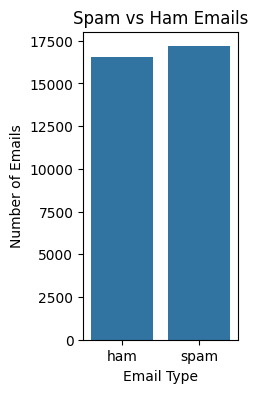

In [18]:
plt.figure(figsize=(2,4))

sns.countplot(data=df, x='Spam/Ham')

plt.xlabel('Email Type')
plt.ylabel('Number of Emails')
plt.title('Spam vs Ham Emails')
plt.show()

In [20]:
df['Subject']=df['Subject'].fillna('')
df['Message']=df['Message'].fillna('')

In [21]:
df['text'] = df['Subject']+ ' ' +df['Message'] 
df[['Subject','Message','text']].head()

,Subject,Message,text
0,christmas tree farm pictures,,christmas tree farm pictures
1,"vastar resources , inc .","gary , production from the high island larger ...","vastar resources , inc . gary , production fro..."
2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,calpine daily gas nomination - calpine daily g...
3,re : issue,fyi - see note below - already done .\nstella\...,re : issue fyi - see note below - already done...
4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,meter 7268 nov allocation fyi .\n- - - - - - -...


In [23]:
df['label']=df['Spam/Ham'].map({
    'ham' : 0,
    'spam' : 1
})

df[['text','label']].head()

,text,label
0,christmas tree farm pictures,0
1,"vastar resources , inc . gary , production fro...",0
2,calpine daily gas nomination - calpine daily g...,0
3,re : issue fyi - see note below - already done...,0
4,meter 7268 nov allocation fyi .\n- - - - - - -...,0


In [28]:
df=df[['text','label']]
df.head()

,text,label
0,christmas tree farm pictures,0
1,"vastar resources , inc . gary , production fro...",0
2,calpine daily gas nomination - calpine daily g...,0
3,re : issue fyi - see note below - already done...,0
4,meter 7268 nov allocation fyi .\n- - - - - - -...,0


In [29]:
df.isna().sum()

text     0
label    0
dtype: int64

In [30]:
df= df[df['text'].str.strip() != '']

## 12. Text cleaning

Now we clean the email text.

We will:

convert to lowercase  
remove URLs  
remove email addresses  
remove punctuation  
remove numbers  
remove extra spaces

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33716 entries, 0 to 33715
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    33716 non-null  object
 1   label   33716 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 526.9+ KB


In [34]:
def clean_text(text):
    text=text.lower()

    text= re.sub(r'http\S+|www\S+|https\S+','',text)

    text=re.sub(r'\S+@\S+','',text)

    text = text.translate(str.maketrans('','',string.punctuation))

    text= re.sub(r'\d+','',text)

    text= re.sub(r'\s+',' ',text).strip()
    
    return text

In [35]:
df['clean_text']=df['text'].apply(clean_text)
df[['text','clean_text']].head()

,text,clean_text
0,christmas tree farm pictures,christmas tree farm pictures
1,"vastar resources , inc . gary , production fro...",vastar resources inc gary production from the ...
2,calpine daily gas nomination - calpine daily g...,calpine daily gas nomination calpine daily gas...
3,re : issue fyi - see note below - already done...,re issue fyi see note below already done stell...
4,meter 7268 nov allocation fyi .\n- - - - - - -...,meter nov allocation fyi forwarded by lauri a ...


In [41]:
df['text_length']=df['text'].apply(len)

df.head()

,text,label,clean_text,text_length
0,christmas tree farm pictures,0,christmas tree farm pictures,29
1,"vastar resources , inc . gary , production fro...",0,vastar resources inc gary production from the ...,4307
2,calpine daily gas nomination - calpine daily g...,0,calpine daily gas nomination calpine daily gas...,67
3,re : issue fyi - see note below - already done...,0,re issue fyi see note below already done stell...,1182
4,meter 7268 nov allocation fyi .\n- - - - - - -...,0,meter nov allocation fyi forwarded by lauri a ...,1150


In [42]:
df.groupby('label')['text_length'].mean()

label
0    1708.443034
1    1612.129113
Name: text_length, dtype: float64

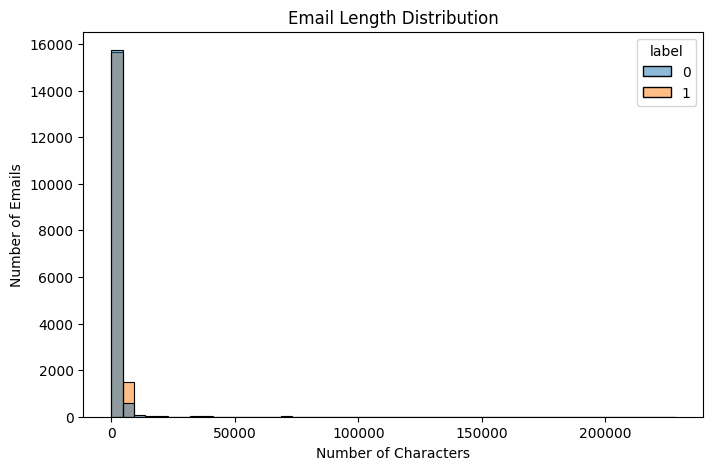

In [47]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='text_length',
    hue='label',
    bins=50
)

plt.title("Email Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Emails")

plt.show()

In [51]:
X = df['clean_text']
y = df['label']

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify=y
)

In [53]:
tfidf = TfidfVectorizer(
    max_features = 5000,
    stop_words='english',
    ngram_range=(1, 2)
)

In [56]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [57]:
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (26972, 5000)
Testing shape: (6744, 5000)


In [59]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [61]:
y_pred = model.predict(X_test_tfidf)

print(y_pred[:20])

[1 1 1 0 1 1 0 0 1 0 1 1 0 1 1 1 0 1 0 0]


In [62]:
accuracy = accuracy_score(y_test,y_pred)

print("Accuracy:",accuracy)

Accuracy: 0.9985172004744959


In [63]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham','Spam']
))

              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00      3309
        Spam       1.00      1.00      1.00      3435

    accuracy                           1.00      6744
   macro avg       1.00      1.00      1.00      6744
weighted avg       1.00      1.00      1.00      6744



In [64]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[3299   10]
 [   0 3435]]


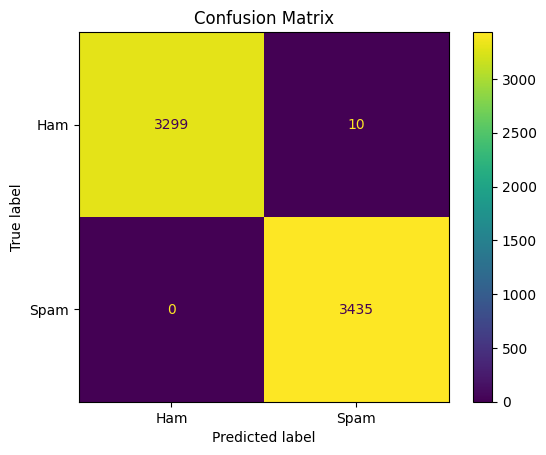

In [65]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels = ['Ham','Spam']
)

disp.plot()

plt.title('Confusion Matrix')
plt.show()


In [66]:
def predict_email(email):
    
    cleaned = clean_text(email)
    
    email_vector = tfidf.transform([cleaned])
    
    prediction = model.predict(email_vector)[0]
    
    probability = model.predict_proba(email_vector)[0]
    
    if prediction == 1:
        result = "SPAM / SUSPICIOUS"
    else:
        result = "HAM / LEGITIMATE"
    
    print("Prediction:", result)
    print("Spam Probability:", round(probability[1] * 100, 2), "%")
    print("Ham Probability:", round(probability[0] * 100, 2), "%")

In [69]:
email = """
Congratulations! You have won $1,000,000.
Click the link below immediately to claim your prize.
"""

predict_email(email)

Prediction: HAM / LEGITIMATE
Spam Probability: 0.31 %
Ham Probability: 99.69 %


In [70]:
email = """
Hi Naveen,

Please attend the project meeting tomorrow at 10 AM.
We will discuss the project progress.

Regards,
Team
"""

predict_email(email)

Prediction: HAM / LEGITIMATE
Spam Probability: 0.11 %
Ham Probability: 99.89 %


In [82]:
data='''Subject: Important Security Alert

Your online banking account has been temporarily restricted due to suspicious activity.

Please confirm your account information immediately to restore access.

Failure to verify your information may result in permanent account suspension.'''
predict_email(data)

Prediction: HAM / LEGITIMATE
Spam Probability: 0.39 %
Ham Probability: 99.61 %


In [71]:
feature_names = tfidf.get_feature_names_out()

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients
})

In [72]:
spam_words = feature_importance.sort_values(
    by="coefficient",
    ascending=False
)

spam_words.head(20)

,word,coefficient
4677,ubs,5.527034
2373,ivanhoe,4.832138
941,cost,3.053654
4476,tenaska,3.046378
4670,type,2.794249
4621,transfers,2.759267
4478,tenaska iv,2.708126
2366,iv,2.664289
1819,fred,2.651730
2147,hsbc,2.515709


In [73]:
ham_words = feature_importance.sort_values(
    by="coefficient",
    ascending=True
)

ham_words.head(20)

,word,coefficient
1314,ect,-2.003108
4808,vince,-1.255098
1081,deal,-1.161826
2663,load,-1.125828
2106,hou,-1.026829
2107,hou ect,-0.978797
2874,meeting,-0.972262
3596,progress,-0.869968
1318,ect ect,-0.861999
2131,hpl,-0.833894


In [75]:
import joblib

joblib.dump(model, "fake_email_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [76]:
model = joblib.load("fake_email_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")